# HORDE — Full dataset only

**Models**
- Reasoning: `Qwen/Qwen2.5-3B-Instruct`
- VLM: `Qwen/Qwen2.5-VL-3B-Instruct`
- Detection: `IDEA-Research/grounding-dino-base`

This notebook runs the **full dataset loop only** (no single-sample path).


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0 — Install & imports


In [2]:
!pip install -q "transformers>=4.46.0" accelerate pillow networkx matplotlib opencv-python-headless num2words
!pip install -q ortools || echo "OR-Tools optional"


In [3]:
import os
import re
import gc
import json
import time
import shutil
import copy
from pathlib import Path
from collections import defaultdict
from typing import List, Dict, Any, Optional, Tuple
from datetime import datetime, timezone

import torch
import numpy as np
from PIL import Image, ImageDraw
import networkx as nx
import matplotlib.pyplot as plt

try:
    from ortools.sat.python import cp_model
    HAS_ORTOOLS = True
except ImportError:
    HAS_ORTOOLS = False

print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("OR-Tools:", HAS_ORTOOLS)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32


Torch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4
OR-Tools: True


In [4]:
# cp -r '/content/drive/MyDrive/Research Paper/vlm' '/content/vlm'

import os
import zipfile

zip_path = '/content/drive/MyDrive/vlm/web_data.zip'
extract_path = '/content/vlm'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print("Files extracted to:", extract_path)



Extraction completed!
Files extracted to: /content/vlm


## 1 — Dataset config (full dataset paths only)


In [5]:
DATA_ROOT = Path("/content/vlm")
JSON_PATH = DATA_ROOT / "web_data" / "web_v1.json"
IMAGE_DIRS = [
    DATA_ROOT / "web_data" / "images",
    DATA_ROOT / "images",
    Path("/content"),
]

def find_image(filename: str, search_dirs: List[Path]) -> Optional[Path]:
    for d in search_dirs:
        p = d / filename
        if p.exists():
            return p
        if d.exists():
            matches = list(d.rglob(filename))
            if matches:
                return matches[0]
    return None


def load_dataset(json_path: Path):
    if not json_path.exists():
        return None
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    if isinstance(data, list):
        return data
    for key in ("data", "questions", "annotations"):
        if key in data and isinstance(data[key], list):
            return data[key]
    return None

_records = load_dataset(JSON_PATH)
print("Dataset size:", len(_records) if _records else 0)
if _records:
    print("Example keys:", list(_records[0].keys()))


Dataset size: 19
Example keys: ['question_id', 'type', 'image', 'text', 'label']


## 2 — Load models


In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

REASONING_NAME = "Qwen/Qwen2.5-3B-Instruct"
print("Loading Qwen2.5-3B-Instruct …")
reasoning_tokenizer = AutoTokenizer.from_pretrained(REASONING_NAME)
reasoning_model = AutoModelForCausalLM.from_pretrained(
    REASONING_NAME, torch_dtype=dtype, low_cpu_mem_usage=True,
).to(device)
reasoning_model.eval()
print("Qwen2.5-3B-Instruct ready.")


Loading Qwen2.5-3B-Instruct …


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Qwen2.5-3B-Instruct ready.


In [7]:
def run_reasoning(prompt: str, max_new_tokens: int = 256, temperature: float = 0.2) -> str:
    """Generate text with Qwen2.5-3B (chat template)."""
    messages = [{"role": "user", "content": prompt}]
    input_text = reasoning_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = reasoning_tokenizer(input_text, return_tensors="pt").to(device)
    with torch.inference_mode():
        out = reasoning_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=temperature > 0,
            temperature=max(temperature, 1e-5),
            pad_token_id=reasoning_tokenizer.eos_token_id,
        )
    gen = out[0][inputs["input_ids"].shape[-1]:]
    return reasoning_tokenizer.decode(gen, skip_special_tokens=True).strip()


def extract_json(text: str) -> Any:
    """Best-effort JSON extraction from model output."""
    text = text.strip()
    # strip markdown fences
    text = re.sub(r"^```(?:json)?\s*", "", text)
    text = re.sub(r"\s*```$", "", text)
    # try whole string
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        pass
    # find first {…} or […]
    for pat in (r"\{[\s\S]*\}", r"\[[\s\S]*\]"):
        m = re.search(pat, text)
        if m:
            try:
                return json.loads(m.group(0))
            except json.JSONDecodeError:
                continue
    raise ValueError(f"Could not parse JSON from:\n{text[:400]}")


In [8]:
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

DINO_NAME = "IDEA-Research/grounding-dino-base"
print("Loading Grounding DINO Base …")
dino_processor = AutoProcessor.from_pretrained(DINO_NAME)
dino_model = AutoModelForZeroShotObjectDetection.from_pretrained(
    DINO_NAME, torch_dtype=dtype,
).to(device)
dino_model.eval()
print("Grounding DINO Base ready.")


Loading Grounding DINO Base …


Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

Grounding DINO Base ready.


In [9]:
def detect_objects(
    image: Image.Image,
    object_labels: List[str],
    box_threshold: float = 0.25,
    text_threshold: float = 0.25,
) -> List[Dict]:
    """Return list of {label, score, box=[x0,y0,x1,y1]}."""
    if not object_labels:
        return []

    # Grounding DINO expects lowercase labels separated by period
    text = " . ".join(o.lower().strip() for o in object_labels) + " ."
    inputs = dino_processor(images=image, text=text, return_tensors="pt")

    # Cast floating tensors to the model dtype (fixes float vs Half error)
    model_dtype = next(dino_model.parameters()).dtype
    for k, v in list(inputs.items()):
        if torch.is_floating_point(v):
            inputs[k] = v.to(device=device, dtype=model_dtype)
        else:
            inputs[k] = v.to(device=device)

    with torch.inference_mode():
        outputs = dino_model(**inputs)

    target_sizes = [image.size[::-1]]  # (h, w)

    # Support both old (box_threshold=) and new (threshold=) transformers APIs
    post_kwargs = dict(
        outputs=outputs,
        input_ids=inputs.input_ids,
        text_threshold=text_threshold,
        target_sizes=target_sizes,
    )
    try:
        results = dino_processor.post_process_grounded_object_detection(
            **post_kwargs, threshold=box_threshold
        )[0]
    except TypeError:
        results = dino_processor.post_process_grounded_object_detection(
            **post_kwargs, box_threshold=box_threshold
        )[0]

    detections = []
    boxes = results["boxes"].detach().cpu().tolist()
    scores = results["scores"].detach().cpu().tolist()
    labels = results.get("text_labels") or results.get("labels") or []
    if hasattr(labels, "tolist"):
        labels = labels.tolist()

    for box, score, label in zip(boxes, scores, labels):
        detections.append({
            "label": label if isinstance(label, str) else str(label),
            "score": float(score),
            "box": [float(x) for x in box],
        })
    return detections


In [10]:
from transformers import AutoProcessor, AutoModelForImageTextToText

VLM_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"
if device == "cuda" and torch.cuda.is_bf16_supported():
    vlm_dtype = torch.bfloat16
elif device == "cuda":
    vlm_dtype = torch.float16
else:
    vlm_dtype = torch.float32

print("Loading Qwen2.5-VL-3B-Instruct …")
vlm_processor = AutoProcessor.from_pretrained(VLM_NAME)
vlm_model = AutoModelForImageTextToText.from_pretrained(
    VLM_NAME, torch_dtype=vlm_dtype, low_cpu_mem_usage=True,
).to(device)
vlm_model.eval()
print("Qwen2.5-VL-3B-Instruct ready.")


Loading Qwen2.5-VL-3B-Instruct …


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Qwen2.5-VL-3B-Instruct ready.


In [11]:
def run_vlm(image, prompt, max_new_tokens=128, temperature=0.0):
    """Qwen2.5-VL-3B-Instruct single-turn generation."""
    image = image.convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt},
        ],
    }]

    try:
        inputs = vlm_processor.apply_chat_template(
            messages,
            add_generation_prompt=True,
            tokenize=True,
            return_dict=True,
            return_tensors="pt",
        )
    except Exception:
        messages_fallback = [{
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": prompt},
            ],
        }]
        text = vlm_processor.apply_chat_template(
            messages_fallback, add_generation_prompt=True, tokenize=False
        )
        inputs = vlm_processor(text=text, images=[image], return_tensors="pt")

    moved = {}
    for k, v in inputs.items():
        if not hasattr(v, "to"):
            moved[k] = v
            continue
        if torch.is_floating_point(v):
            moved[k] = v.to(device=device, dtype=vlm_dtype)
        else:
            moved[k] = v.to(device=device)
    inputs = moved

    gen_kwargs = {
        "max_new_tokens": max_new_tokens,
        "do_sample": bool(temperature and temperature > 0),
        "pad_token_id": vlm_processor.tokenizer.eos_token_id,
    }
    if gen_kwargs["do_sample"]:
        gen_kwargs["temperature"] = max(float(temperature), 1e-5)

    with torch.inference_mode():
        out = vlm_model.generate(**inputs, **gen_kwargs)

    in_len = inputs["input_ids"].shape[-1]
    return vlm_processor.tokenizer.decode(out[0][in_len:], skip_special_tokens=True).strip()


print("run_vlm ready (Qwen2.5-VL-3B-Instruct).")


run_vlm ready (Qwen2.5-VL-3B-Instruct).


In [12]:
def optimize_relation_graph(
    candidates: List[Dict],
    max_relations: int = 6,
    min_score: float = 0.25,
) -> List[Dict]:
    """
    Select a subset of relations that maximises total score under:
    - at most max_relations
    - no contradictory pairs on the same (subject, object) with different relations
    - prefer higher-scoring edges
    """
    cands = [c for c in candidates if c["score"] >= min_score]
    if not cands:
        return []

    if HAS_ORTOOLS:
        model = cp_model.CpModel()
        n = len(cands)
        x = [model.NewBoolVar(f"r{i}") for i in range(n)]
        model.Maximize(sum(int(c["score"] * 1000) * x[i] for i, c in enumerate(cands)))
        model.Add(sum(x) <= max_relations)
        pairs = defaultdict(list)
        for i, c in enumerate(cands):
            pairs[(c["subject"], c["object"])].append(i)
        for idxs in pairs.values():
            if len(idxs) > 1:
                model.Add(sum(x[i] for i in idxs) <= 1)
        solver = cp_model.CpSolver()
        solver.parameters.max_time_in_seconds = 5.0
        status = solver.Solve(model)
        if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
            return [cands[i] for i in range(n) if solver.Value(x[i]) == 1]

    selected = []
    used_endpoints = set()
    for c in sorted(cands, key=lambda z: -z["score"]):
        ep = (c["subject"], c["object"])
        if ep in used_endpoints:
            continue
        selected.append(c)
        used_endpoints.add(ep)
        if len(selected) >= max_relations:
            break
    return selected


print("optimize_relation_graph ready (used by full dataset loop).")

optimize_relation_graph ready (used by full dataset loop).


In [13]:
def contrastive_decode(
    image: Image.Image,
    base_prompt: str,
    pos_prompt: str,
    cf_prompt: str,
    alpha: float = 0.6,
    beta: float = 0.4,
    max_new_tokens: int = 16,
    temperature: float = 0.0,
) -> str:
    """
    Contrastive decoding for Qwen2.5-VL.
    Rebuilds full multimodal inputs each step so RoPE / masks stay aligned.
    Stops early on clear yes/no and blocks token repetition (yesyesyes...).
    """
    image = image.convert("RGB")
    eos_id = vlm_processor.tokenizer.eos_token_id
    generated: list[int] = []

    def logits_for(prompt: str, partial_text: str):
        full_prompt = prompt
        if partial_text:
            full_prompt = prompt.rstrip() + " " + partial_text

        messages = [{
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": full_prompt},
            ],
        }]
        try:
            inputs = vlm_processor.apply_chat_template(
                messages,
                add_generation_prompt=True,
                tokenize=True,
                return_dict=True,
                return_tensors="pt",
            )
        except Exception:
            text = vlm_processor.apply_chat_template(
                messages, add_generation_prompt=True, tokenize=False
            )
            inputs = vlm_processor(text=text, images=[image], return_tensors="pt")

        model_dtype = next(vlm_model.parameters()).dtype
        moved = {}
        for k, v in inputs.items():
            if not hasattr(v, "to"):
                moved[k] = v
                continue
            if torch.is_floating_point(v):
                moved[k] = v.to(device=device, dtype=model_dtype)
            else:
                moved[k] = v.to(device=device)
        inputs = moved

        with torch.inference_mode():
            out = vlm_model(**inputs)
        return out.logits[:, -1, :].float()

    for step in range(max_new_tokens):
        partial = vlm_processor.tokenizer.decode(
            generated, skip_special_tokens=True
        )

        base_logits = logits_for(base_prompt, partial)
        pos_logits  = logits_for(pos_prompt, partial)
        cf_logits   = logits_for(cf_prompt, partial)

        guided = (
            base_logits
            + alpha * (pos_logits - base_logits)
            - beta  * (cf_logits - base_logits)
        )

        # Block immediate repetition of the last token (stops yesyesyes...)
        if generated:
            guided[0, generated[-1]] = -1e9

        if temperature and temperature > 1e-5:
            probs = torch.softmax(guided / temperature, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
        else:
            next_token = torch.argmax(guided, dim=-1, keepdim=True)

        token_id = int(next_token.item())
        if token_id == eos_id:
            break
        generated.append(token_id)

        text_so_far = vlm_processor.tokenizer.decode(
            generated, skip_special_tokens=True
        ).strip().lower()

        # Stop as soon as we have a clean yes/no
        if text_so_far in {"yes", "no", "yes.", "no."}:
            break
        # Stop if yes/no appears once as a whole word
        yn = re.findall(r"\b(yes|no)\b", text_so_far)
        if len(yn) == 1 and len(text_so_far) <= 8:
            break
        # Safety: if the same word is glued (yesyes), collapse and stop
        if re.fullmatch(r"(yes)+", text_so_far.replace(" ", "")):
            generated = vlm_processor.tokenizer.encode(
                "yes", add_special_tokens=False
            )
            break
        if re.fullmatch(r"(no)+", text_so_far.replace(" ", "")):
            generated = vlm_processor.tokenizer.encode(
                "no", add_special_tokens=False
            )
            break

    answer = vlm_processor.tokenizer.decode(
        generated, skip_special_tokens=True
    ).strip()

    # Final cleanup for repeated yes/no
    low = answer.lower().replace(" ", "")
    if re.fullmatch(r"(yes)+[\.!]?", low):
        answer = "yes"
    elif re.fullmatch(r"(no)+[\.!]?", low):
        answer = "no"
    return answer


print("contrastive_decode ready (used by full dataset loop).")


contrastive_decode ready (used by full dataset loop).


In [14]:
def extract_relations_from_answer(answer: str, question: str) -> List[Dict]:
    prompt = f"""Extract the visual claims (subject-relation-object) implied by the answer.

Question: {question}
Answer: {answer}

Return ONLY a JSON list:
[
  {{"subject": "...", "relation": "...", "object": "...", "span": "exact phrase from answer"}}
]
If the answer is a simple yes/no with no explicit relation, return [].
"""
    raw = run_reasoning(prompt, max_new_tokens=200)
    try:
        data = extract_json(raw)
        if isinstance(data, dict):
            data = data.get("claims", data.get("relations", []))
        if not isinstance(data, list):
            return []
        out = []
        for c in data:
            if not isinstance(c, dict):
                continue
            s = str(c.get("subject", "")).strip().lower()
            r = str(c.get("relation", "")).strip().lower().replace(" ", "_")
            o = str(c.get("object", "")).strip().lower()
            span = str(c.get("span", "")).strip()
            if s and r and o:
                out.append({"subject": s, "relation": r, "object": o, "span": span})
        return out
    except Exception:
        return []


def verify_claims_with_vlm(
    image: Image.Image,
    answer: str,
    claims: List[Dict],
    gq_star: List[Dict],
    question_text: str = "",
    critical_action: str = None,
) -> Dict:
    """Return acceptable / not_acceptable only (no Supported/Conflicting/Uncertain)."""
    claims_txt = json.dumps(claims, indent=2) if claims else "[]"
    gq_txt = json.dumps(
        [{"subject": r["subject"], "relation": r["relation"], "object": r["object"]} for r in gq_star],
        indent=2,
    )
    q = question_text or question
    prompt = f"""Check if this answer is acceptable for the image.

Question: {q}
Answer: {answer}
Claims: {claims_txt}
Image relations: {gq_txt}
Critical action (must be true for yes): {critical_action or "none"}

Rules:
- Judge only from the image.
- Object present does not mean the action is true.
- If the answer matches the image, it is acceptable.
- If the answer is wrong for the image, it is not_acceptable.

Return ONLY JSON:
{{
  "acceptable": true or false,
  "recommended_answer": "yes or no or short corrected answer"
}}
"""
    raw = run_vlm(image, prompt, max_new_tokens=200, temperature=0.1)
    try:
        result = extract_json(raw)
        acc = result.get("acceptable", None)
        if isinstance(acc, str):
            acc = acc.strip().lower() in ("true", "yes", "1", "acceptable")
        if acc is None:
            # fallback from legacy status keys if model returns them
            st = str(result.get("overall_status", "")).lower()
            acc = st in ("supported", "acceptable")
        result["acceptable"] = bool(acc)
        result["overall_status"] = "acceptable" if result["acceptable"] else "not_acceptable"
        return result
    except Exception as e:
        return {
            "acceptable": False,
            "overall_status": "not_acceptable",
            "recommended_answer": answer,
            "parse_error": str(e),
        }


## 3 — Full dataset evaluation

Runs **every** sample in `web_v1.json` in order.

- Appends each result to `/content/horde_full_results.json`
- Cleans memory after each sample
- Prints final **accuracy**, confusion matrix, plots
- Extra metrics on **baseline-wrong** subset only


Dataset size: 19

[1/19] id=1  bicycle_has_1wheel.jpg
Q: Is there bicycle has two wheels in the photo?
ref=no  pred=no  correct=True

[2/19] id=2  car_without_wheel.jpg
Q: Is there car has four wheels in the photo?
ref=no  pred=yes  correct=False

[3/19] id=3  plane_on_city.jpg
Q: Is there plane on runway in the photo?
ref=no  pred=no  correct=True

[4/19] id=4  train_on_fly.jpg
Q: Is there train on rail in the photo?
ref=no  pred=no  correct=True

[5/19] id=5  running_bird.jpg
Q: Is there bird flying on a beach in the photo?
ref=no  pred=no  correct=True

[6/19] id=6  running_bird.jpg
Q: Is there bird flying on the air in the photo?
ref=no  pred=no  correct=True

[7/19] id=7  plane_without_wing.jpg
Q: Is there plane has wings in the photo?
ref=no  pred=no  correct=True

[8/19] id=8  fish_fly.jpg
Q: Is there fish swimming in the water in the photo?
ref=no  pred=no  correct=True

[9/19] id=9  horse_without_tail.jpg
Q: Is there horse has tail in the photo?
ref=no  pred=no  correct=True



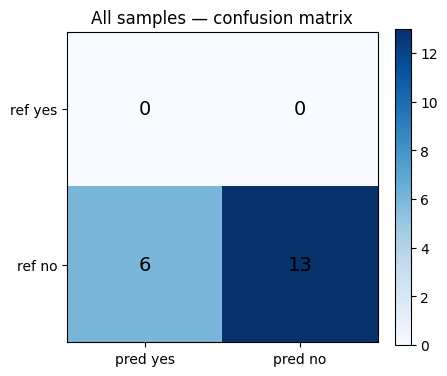

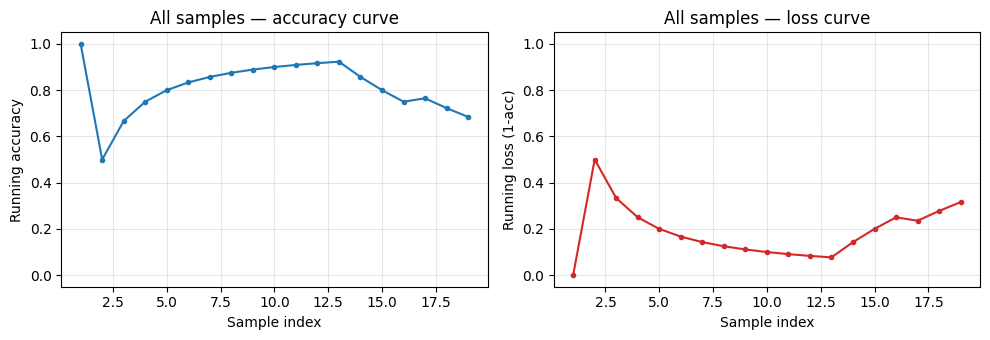


BASELINE-INCORRECT SUBSET
Count: 6 / 19
Accuracy on baseline-wrong cases: 0.0000  (0/6)
Confusion matrix: {'yes_yes': 0, 'yes_no': 0, 'no_yes': 6, 'no_no': 0}


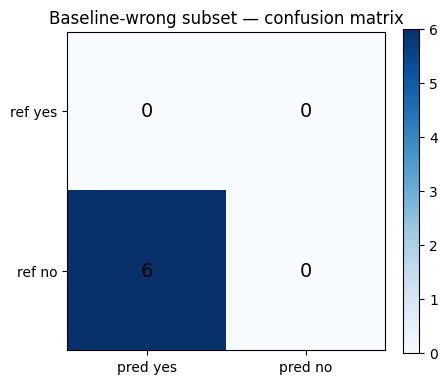

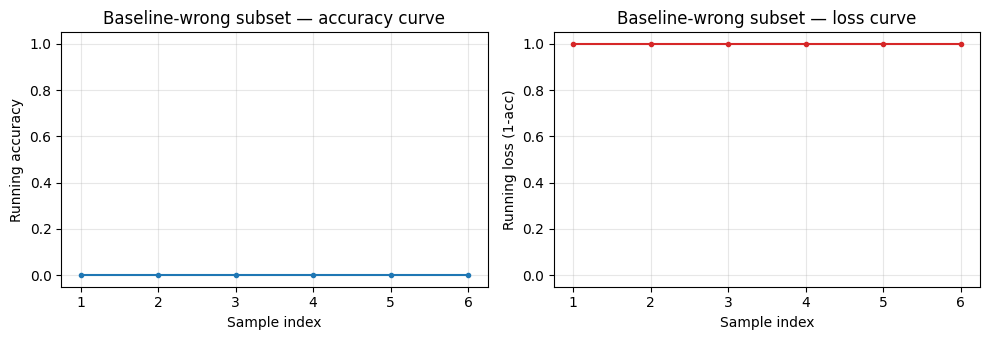


Saved: /content/horde_full_results.json
Saved: /content/horde_metrics.json
{
  "n_samples": 19,
  "accuracy": 0.6842,
  "correct": 13,
  "confusion_matrix": {
    "yes_yes": 0,
    "yes_no": 0,
    "no_yes": 6,
    "no_no": 13
  },
  "baseline_wrong_n": 6,
  "baseline_wrong_accuracy": 0.0,
  "baseline_wrong_confusion_matrix": {
    "yes_yes": 0,
    "yes_no": 0,
    "no_yes": 6,
    "no_no": 0
  }
}


In [15]:
# ---- FULL DATASET EVALUATION (simple results) ----
import time
import shutil
from datetime import datetime, timezone
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

RESULTS_JSON = Path("/content/horde_full_results.json")
METRICS_JSON = Path("/content/horde_metrics.json")
TEMP_DIR = Path("/content/horde_temp")
TEMP_DIR.mkdir(parents=True, exist_ok=True)

MAX_RETRY = 2


def ensure_dino_loaded():
    global dino_model, dino_processor
    if "dino_model" in globals() and dino_model is not None:
        return
    print("Reloading Grounding DINO …")
    from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
    name = globals().get("DINO_NAME", "IDEA-Research/grounding-dino-base")
    dino_processor = AutoProcessor.from_pretrained(name)
    dino_model = AutoModelForZeroShotObjectDetection.from_pretrained(
        name, torch_dtype=dtype
    ).to(device)
    dino_model.eval()


def cleanup_after_sample():
    if "counterfactual_images" in globals() and isinstance(counterfactual_images, dict):
        counterfactual_images.clear()
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def normalize_yes_no(answer) -> str:
    """Unparsed / unclear → no."""
    text = str(answer).strip().lower().strip(" .,!\"'")
    if text in {"yes", "yes.", "yes!"}:
        return "yes"
    if text in {"no", "no.", "no!"}:
        return "no"
    matches = re.findall(r"\b(yes|no)\b", text)
    if len(matches) == 1:
        return matches[0]
    return "no"


def to_yes_no(text: str):
    t = str(text).strip().lower()
    if not t:
        return None
    if re.search(r"\bnot\b.*\b(on|in|there|present|flying|running)\b", t):
        return "no"
    if any(p in t for p in ["is not", "are not", "there is no", "there are no", "not flying", "not on"]):
        return "no"
    m = re.findall(r"\b(yes|no)\b", t)
    if len(m) == 1:
        return m[0]
    if t in {"yes", "no", "yes.", "no."}:
        return t.rstrip(".")
    return None


def run_horde_on_record(rec: dict, sample_idx: int) -> dict:
    t0 = time.perf_counter()
    q = rec.get("text") or rec.get("question") or ""
    img_name = rec.get("image") or rec.get("image_path") or ""
    ref_raw = rec.get("label") or rec.get("answer")
    qid = rec.get("question_id", sample_idx + 1)

    img_path = find_image(img_name, IMAGE_DIRS)
    if img_path is None:
        return {
            "question_id": qid,
            "image": img_name,
            "question": q,
            "reference": normalize_yes_no(ref_raw) if ref_raw is not None else "no",
            "prediction_answer": "no",
            "prediction_answer_correct": False,
            "baseline_answer": "",
            "baseline_prediction": "no",
            "horde_answer": "no",
            "horde_prediction": "no",
        }

    image = Image.open(img_path).convert("RGB")

    # question analysis
    try:
        raw_qa = run_reasoning(
            f"""Analyze and return ONLY JSON.
Question: {q}
Schema:
{{"relevant_objects":[],"question_type":"yes_no|open|counting|attribute|other",
 "critical_action":"verb or null","critical_attribute":null,"count_target":null,"focus":"..."}}
Rules: extract action verbs; object present does not mean action is true.
""",
            max_new_tokens=220,
        )
        qa = extract_json(raw_qa)
    except Exception:
        words = re.findall(r"[a-zA-Z]+", q.lower())
        action_verbs = {"flying", "running", "riding", "sitting", "standing", "holding", "walking"}
        found_action = next((w for w in words if w in action_verbs), None)
        stop = {"is", "are", "the", "a", "an", "in", "on", "of", "to", "what", "there", "photo", "image"}
        objs = [w for w in words if w not in stop and len(w) > 2][:5]
        qtype = "yes_no" if q.lower().startswith(("is ", "are ", "does ", "do ")) else "open"
        qa = {
            "relevant_objects": objs or ["object"],
            "question_type": qtype,
            "critical_action": found_action,
            "critical_attribute": None,
            "count_target": None,
            "focus": q,
        }
    qa.setdefault("critical_action", None)
    object_labels_local = qa.get("relevant_objects") or []

    ensure_dino_loaded()
    try:
        dets = detect_objects(image, object_labels_local)
    except Exception:
        dets = []
    detected_names_local = sorted({d["label"].lower() for d in dets}) or object_labels_local

    # multi-agent
    rel_tmpl = """Visual inspector only.
Question: {question}
Objects: {objects}
Detected: {detected}
Critical action: {crit_action}

Return ONLY JSON list of visible relations:
[{{"subject":"...","relation":"...","object":"...","type":"action|spatial|attribute"}}]
Object present does NOT mean action is true. Report true action only.
Empty [] allowed.
"""
    agent_preds = []
    for agent_id in range(4):
        prompt = rel_tmpl.format(
            question=q,
            objects=", ".join(object_labels_local),
            detected=", ".join(detected_names_local) or "none",
            crit_action=qa.get("critical_action") or "none",
        )
        try:
            raw = run_vlm(image, prompt, max_new_tokens=140, temperature=0.15 + 0.1 * agent_id)
            preds = extract_json(raw)
            if isinstance(preds, dict):
                preds = preds.get("relations", preds.get("relations_list", [preds]))
            if not isinstance(preds, list):
                preds = []
        except Exception:
            preds = []
        clean = []
        for p in preds:
            if not isinstance(p, dict):
                continue
            s = str(p.get("subject", "")).strip().lower()
            r = str(p.get("relation", "")).strip().lower().replace(" ", "_")
            o = str(p.get("object", "")).strip().lower()
            t = str(p.get("type", "action")).strip().lower()
            if s and r and o:
                clean.append({"subject": s, "relation": r, "object": o, "type": t})
        agent_preds.append(clean)

    agg = defaultdict(lambda: {"count": 0, "type": "action"})
    for preds in agent_preds:
        seen = set()
        for p in preds:
            k = (p["subject"], p["relation"], p["object"])
            if k in seen:
                continue
            seen.add(k)
            agg[k]["count"] += 1
            agg[k]["type"] = p.get("type", "action")

    candidates = []
    for (subj, rel, obj), info in agg.items():
        agreement = info["count"] / 4.0
        labels = {d["label"].lower() for d in dets}
        s_hit = any(subj in lab or lab in subj for lab in labels)
        o_hit = any(obj in lab or lab in obj for lab in labels)
        vis = 1.0 if (s_hit and o_hit) else (0.55 if (s_hit or o_hit) else 0.2)
        score = 0.45 * agreement + 0.3 * vis + 0.25 * (1.0 if qa.get("critical_action") and qa["critical_action"] in rel else 0.4)
        candidates.append({
            "subject": subj, "relation": rel, "object": obj,
            "type": info["type"],
            "agreement_count": info["count"],
            "agreement_score": agreement,
            "visual_score": vis,
            "score": score,
            "q_relevance": 0.5,
        })
    candidates = [c for c in candidates if c["agreement_count"] >= 2 or c["visual_score"] >= 0.9] or candidates
    optimized = optimize_relation_graph(candidates)

    E_plus = [
        {"subject": r["subject"], "relation": r["relation"], "object": r["object"], "score": r["score"]}
        for r in optimized if r["visual_score"] >= 0.5
    ]
    alternatives = []
    if qa.get("critical_action") and object_labels_local:
        alts = {
            "flying": ["running", "standing", "walking"],
            "running": ["flying", "standing"],
            "riding": ["standing_beside", "walking"],
        }
        for alt in alts.get(qa["critical_action"], ["standing_beside"]):
            alternatives.append({
                "subject": object_labels_local[0],
                "relation": alt,
                "object": object_labels_local[1] if len(object_labels_local) > 1 else "ground",
            })

    def fmt_ev(ev_list, title):
        if not ev_list:
            return f"{title}: none.\n"
        lines = [f"{title}:"] + [f"- {e.get('subject')} {e.get('relation')} {e.get('object')}" for e in ev_list]
        return "\n".join(lines) + "\n"

    pos_text = fmt_ev(E_plus, "Supported relations")
    cf_text = fmt_ev(alternatives, "Do not treat as true")

    is_yn = str(qa.get("question_type", "")).lower() in {"yes_no", "yes/no"} or q.strip().lower().startswith(
        ("is ", "are ", "does ", "do ")
    )
    action_hint = ""
    if qa.get("critical_action"):
        action_hint = (
            f" Answer YES only if action '{qa['critical_action']}' is visible. "
            f"Object presence alone is not enough."
        )

    if is_yn:
        base_p = f"Answer with ONLY yes or no.{action_hint}\nQuestion: {q}\nAnswer:"
        pos_p = f"{pos_text}\nAnswer with ONLY yes or no.{action_hint}\nQuestion: {q}\nAnswer:"
        cf_p = f"{cf_text}\nAnswer with ONLY yes or no.{action_hint}\nQuestion: {q}\nAnswer:"
        max_tok = 8
    else:
        base_p = f"Answer from the image only. Be concise.{action_hint}\nQuestion: {q}"
        pos_p = f"{pos_text}\nAnswer briefly.{action_hint}\nQuestion: {q}"
        cf_p = f"{cf_text}\nAnswer briefly.{action_hint}\nQuestion: {q}"
        max_tok = 40

    try:
        baseline = run_vlm(image, base_p, max_new_tokens=max_tok, temperature=0.0)
    except Exception as e:
        baseline = "no"

    try:
        candidate = contrastive_decode(
            image, base_p, pos_p, cf_p, alpha=0.6, beta=0.4, max_new_tokens=max_tok
        )
    except Exception:
        candidate = baseline

    final = candidate
    for attempt in range(1, MAX_RETRY + 1):
        try:
            claims = extract_relations_from_answer(final, q)
        except Exception:
            claims = []
        try:
            verification = verify_claims_with_vlm(
                image, final, claims, optimized,
                question_text=q,
                critical_action=qa.get("critical_action"),
            )
        except Exception:
            verification = {"acceptable": False, "recommended_answer": final}

        if verification.get("acceptable"):
            break

        recommended = (verification.get("recommended_answer") or "").strip()
        repair = (
            f"Previous answer not acceptable. Suggested: {recommended}\n"
            f"Correct from image only.{action_hint}\n"
            f"If yes/no, answer only yes or no.\nQuestion: {q}"
        )
        try:
            revised = contrastive_decode(
                image, repair, pos_text + "\n" + repair, cf_text + "\n" + repair,
                alpha=0.7, beta=0.5, max_new_tokens=max_tok,
            )
        except Exception:
            revised = final
        if recommended and to_yes_no(recommended):
            revised = to_yes_no(recommended)
        final = revised

    # normalize: unclear → no on yes/no
    pred = to_yes_no(final)
    if pred is None:
        pred = normalize_yes_no(final) if is_yn else (str(final).strip() or "no")
        if is_yn:
            pred = "no" if pred not in ("yes", "no") else pred

    base_pred = normalize_yes_no(baseline)
    ref = normalize_yes_no(ref_raw) if ref_raw is not None else "no"

    # soft action fix
    if is_yn and qa.get("critical_action") and pred == "yes":
        act = qa["critical_action"]
        graph_rels = " ".join(r["relation"] for r in optimized)
        if act not in graph_rels and base_pred == "no":
            pred = "no"

    cleanup_after_sample()

    return {
        "question_id": qid,
        "image": img_name,
        "question": q,
        "reference": ref,
        "prediction_answer": pred,
        "prediction_answer_correct": pred == ref,
        "baseline_answer": str(baseline).strip(),
        "baseline_prediction": base_pred,
        "horde_answer": str(final).strip(),
        "horde_prediction": pred,
    }


def confusion_counts(results, ref_key="reference", pred_key="prediction_answer"):
    cm = {"yes_yes": 0, "yes_no": 0, "no_yes": 0, "no_no": 0}
    for r in results:
        ref = str(r.get(ref_key, "")).lower()
        pred = str(r.get(pred_key, "")).lower()
        if ref not in ("yes", "no"):
            ref = "no"
        if pred not in ("yes", "no"):
            pred = "no"
        cm[f"{ref}_{pred}"] += 1
    return cm


def plot_confusion(cm, title, save_path):
    mat = np.array([
        [cm.get("yes_yes", 0), cm.get("yes_no", 0)],
        [cm.get("no_yes", 0), cm.get("no_no", 0)],
    ], dtype=float)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(mat, cmap="Blues")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["pred yes", "pred no"])
    ax.set_yticklabels(["ref yes", "ref no"])
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(mat[i, j]), ha="center", va="center", color="black", fontsize=14)
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    fig.savefig(save_path, dpi=120)
    plt.show()
    plt.close(fig)


def plot_acc_loss_curves(results, title_prefix, save_prefix):
    """Running accuracy and simple 0-1 loss over sample order."""
    if not results:
        return
    correct = [1.0 if r.get("prediction_answer_correct") else 0.0 for r in results]
    running_acc = np.cumsum(correct) / np.arange(1, len(correct) + 1)
    loss = 1.0 - np.array(correct)  # 0 if correct else 1
    running_loss = np.cumsum(loss) / np.arange(1, len(loss) + 1)
    xs = np.arange(1, len(correct) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(xs, running_acc, marker="o", markersize=3)
    axes[0].set_xlabel("Sample index")
    axes[0].set_ylabel("Running accuracy")
    axes[0].set_title(f"{title_prefix} — accuracy curve")
    axes[0].set_ylim(-0.05, 1.05)
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(xs, running_loss, marker="o", markersize=3, color="C3")
    axes[1].set_xlabel("Sample index")
    axes[1].set_ylabel("Running loss (1-acc)")
    axes[1].set_title(f"{title_prefix} — loss curve")
    axes[1].set_ylim(-0.05, 1.05)
    axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    fig.savefig(f"{save_prefix}_curves.png", dpi=120)
    plt.show()
    plt.close(fig)


# ----- load data -----
all_records = load_dataset(JSON_PATH) or []
print("Dataset size:", len(all_records))

if RESULTS_JSON.exists():
    with open(RESULTS_JSON, "r", encoding="utf-8") as f:
        all_results = json.load(f)
    if isinstance(all_results, dict):
        all_results = all_results.get("results", [])
    done_ids = {r.get("question_id") for r in all_results}
    print("Resuming:", len(all_results), "done")
else:
    all_results = []
    done_ids = set()

# ----- main loop -----
for i, rec in enumerate(all_records):
    qid = rec.get("question_id", i + 1)
    if qid in done_ids:
        print(f"[{i+1}/{len(all_records)}] skip id={qid}")
        continue

    print(f"\n[{i+1}/{len(all_records)}] id={qid}  {rec.get('image')}")
    print("Q:", rec.get("text") or rec.get("question"))

    try:
        sample_out = run_horde_on_record(rec, i)
    except Exception as e:
        print("FAILED:", e)
        sample_out = {
            "question_id": qid,
            "image": rec.get("image"),
            "question": rec.get("text") or rec.get("question"),
            "reference": normalize_yes_no(rec.get("label")),
            "prediction_answer": "no",
            "prediction_answer_correct": False,
            "baseline_answer": "",
            "baseline_prediction": "no",
            "horde_answer": "no",
            "horde_prediction": "no",
        }
        cleanup_after_sample()

    all_results.append(sample_out)
    done_ids.add(qid)

    with open(RESULTS_JSON, "w", encoding="utf-8") as f:
        json.dump(all_results, f, indent=2, ensure_ascii=False)

    print(
        f"ref={sample_out['reference']}  pred={sample_out['prediction_answer']}  "
        f"correct={sample_out['prediction_answer_correct']}"
    )

print("\nDone. Total:", len(all_results))

# ========== EVAL 1: all samples — final prediction vs reference ==========
n = len(all_results)
n_correct = sum(1 for r in all_results if r.get("prediction_answer_correct"))
acc = n_correct / n if n else 0.0
cm_all = confusion_counts(all_results)

print("\n" + "=" * 50)
print("FINAL RESULTS (all samples)")
print("=" * 50)
print(f"Accuracy (acc): {acc:.4f}  ({n_correct}/{n})")
print("Confusion matrix [ref_pred]:", cm_all)
plot_confusion(cm_all, "All samples — confusion matrix", "/content/cm_all.png")
plot_acc_loss_curves(all_results, "All samples", "/content/all")

# ========== EVAL 2: only baseline-incorrect samples ==========
hard = []
for r in all_results:
    base_pred = r.get("baseline_prediction", "no")
    ref = r.get("reference", "no")
    if base_pred != ref:
        hard.append(r)

print("\n" + "=" * 50)
print("BASELINE-INCORRECT SUBSET")
print("=" * 50)
print(f"Count: {len(hard)} / {n}")

if hard:
    n_h = len(hard)
    n_h_ok = sum(1 for r in hard if r.get("prediction_answer_correct"))
    acc_h = n_h_ok / n_h if n_h else 0.0
    cm_h = confusion_counts(hard)
    print(f"Accuracy on baseline-wrong cases: {acc_h:.4f}  ({n_h_ok}/{n_h})")
    print("Confusion matrix:", cm_h)
    plot_confusion(cm_h, "Baseline-wrong subset — confusion matrix", "/content/cm_baseline_wrong.png")
    plot_acc_loss_curves(hard, "Baseline-wrong subset", "/content/baseline_wrong")
else:
    acc_h = None
    cm_h = {}
    print("No baseline-incorrect samples.")

metrics = {
    "n_samples": n,
    "accuracy": round(acc, 4),
    "correct": n_correct,
    "confusion_matrix": cm_all,
    "baseline_wrong_n": len(hard),
    "baseline_wrong_accuracy": round(acc_h, 4) if acc_h is not None else None,
    "baseline_wrong_confusion_matrix": cm_h,
}
with open(METRICS_JSON, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("\nSaved:", RESULTS_JSON)
print("Saved:", METRICS_JSON)
print(json.dumps(metrics, indent=2))


## Summary

**Models:** Qwen2.5-3B · Qwen2.5-VL-3B · grounding-dino-base

**Eval:** full dataset only → `prediction_answer` vs `reference` → accuracy
